Ahmed Amer Alshehri 2230002008 9MA2

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

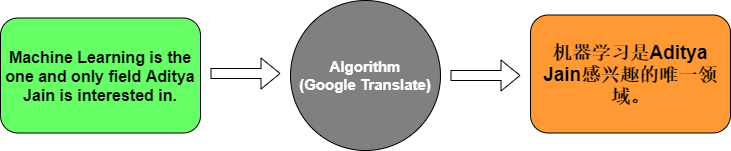

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [2]:
#!pip install tensorflow

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [4]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [6]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [7]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step - accuracy: 0.1429 - loss: 2.4838 - val_accuracy: 0.0000e+00 - val_loss: 2.4870
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.1429 - loss: 2.4741 - val_accuracy: 0.0000e+00 - val_loss: 2.4888
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4642 - val_accuracy: 0.0000e+00 - val_loss: 2.4907
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4537 - val_accuracy: 0.0000e+00 - val_loss: 2.4929
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.5714 - loss: 2.4420 - val_accuracy: 0.0000e+00 - val_loss: 2.4954
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4288 - val_accuracy: 0.0000e+00 - val_loss: 2.4983
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5714 - loss: 2.4137 - val_accuracy: 0.0000e+00 - val_loss: 2.5016
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.3960 - val_accurac

In [8]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. What does the Embedding layer do to a word index?**
It turns each word's integer index (for example `5`) into a dense vector of 64 numbers. The vectors are learned during training, so words that are used in similar ways end up with similar vectors. This is much more compact and informative than a one-hot vector, and it is what the LSTM actually receives as input. (`input_dim = len(eng_word_index) + 1` because index 0 is reserved for padding.)

**3. What is the role of the Encoder LSTM?**
The encoder LSTM reads the English sentence one word (embedding) at a time and keeps updating its memory (hidden state and cell state). Because it uses `LSTM(64)` without `return_sequences`, it outputs only the last state, which is a single 64-number summary of the whole sentence, often called the *context vector*. This vector is the only information about the English sentence that is passed on to the decoder.

**5. What does the Decoder LSTM do?**
`RepeatVector` copies the context vector once for every position of the French sentence, and the decoder LSTM (`return_sequences=True`) reads these copies step by step. At each step it produces a hidden vector that represents "what the French word at this position should be". The Dense layer then converts each of these vectors into scores over the French vocabulary.

**8. Why do we use `softmax` in the final layer?**
The Dense layer gives one raw score for every French word at every time step. `softmax` converts these scores into probabilities that are between 0 and 1 and sum to 1, so the model gives a probability distribution over the French vocabulary at each position. We pick the word with the highest probability (`np.argmax`), and the `sparse_categorical_crossentropy` loss compares this distribution with the true word index during training.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

#### Task 2 solution: English → French translation for an e-commerce company

Steps: (1) download and load the Kaggle dataset, (2) clean the text and keep short sentence pairs, (3) tokenize and pad, (4) build the same encoder-decoder LSTM used above, but larger, (5) train and evaluate, (6) translate new sentences such as product listings and customer reviews.

> Run this on Colab (or any machine with TensorFlow). The first code cell downloads the dataset with `kagglehub`; if the download fails, download the CSV from the Kaggle link above, upload it, and set `csv_path` manually.

In [9]:
%pip install -q kagglehub

import os, glob
import pandas as pd
import kagglehub

try:
    dataset_dir = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
    csv_path = glob.glob(os.path.join(dataset_dir, "**", "*.csv"), recursive=True)[0]
except Exception as e:
    print("Kaggle download failed:", e)
    print("Download the CSV manually, upload it here and set csv_path to its file name.")
    csv_path = "eng_-french.csv"

print("Using file:", csv_path)

df = pd.read_csv(csv_path)
df = df.iloc[:, :2]                      # keep only the two text columns
df.columns = ["english", "french"]
print("Total sentence pairs:", len(df))
df.head()

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
Using file: /kaggle/input/language-translation-englishfrench/eng_-french.csv
Total sentence pairs: 175621


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


**Preprocessing:** lowercase, remove punctuation, drop empty rows and duplicates, keep short sentence pairs (so the model trains in a reasonable time) and take a random sample.

In [10]:
import re
import numpy as np

def clean(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^\w\s']", " ", text)    # \w keeps French accented letters
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = df.dropna().drop_duplicates()
df["english"] = df["english"].map(clean)
df["french"] = df["french"].map(clean)
df = df[(df["english"].str.len() > 0) & (df["french"].str.len() > 0)]

MAX_LEN = 8          # maximum number of words per sentence
NUM_SAMPLES = 20000  # number of sentence pairs used for training/testing

df = df[(df["english"].str.split().str.len() <= MAX_LEN) &
        (df["french"].str.split().str.len() <= MAX_LEN)]
df = df.drop_duplicates(subset="english")
df = df.sample(n=min(NUM_SAMPLES, len(df)), random_state=42).reset_index(drop=True)

print("Sentence pairs used:", len(df))
df.head(10)

Sentence pairs used: 20000


,english,french
0,you must prepare yourself for the worst,tu dois te préparer au pire
1,it's a huge commitment,c'est un engagement énorme
2,you just screwed up,tu viens de foirer
3,how many goats do they have,ils ont combien de chèvres
4,have i left anything out,ai je omis quoi que ce soit
5,you can sit down if you want,tu peux t'asseoir si tu veux
6,this is your book,c'est ton livre
7,have you been listening to me,m'avez vous écouté
8,his failure taught me a good lesson,son échec m'a enseigné une bonne leçon
9,tom didn't appear,tom n'est pas apparu


**Tokenization and padding** (same idea as the small example above, with a limited vocabulary and an `<unk>` token for rare words).

In [11]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 8000

eng_tok = Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>")
eng_tok.fit_on_texts(df["english"])
frn_tok = Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>")
frn_tok.fit_on_texts(df["french"])

eng_vocab = min(VOCAB_SIZE, len(eng_tok.word_index) + 1)
frn_vocab = min(VOCAB_SIZE, len(frn_tok.word_index) + 1)
print("English vocabulary size:", eng_vocab)
print("French vocabulary size:", frn_vocab)

eng_pad = pad_sequences(eng_tok.texts_to_sequences(df["english"]), maxlen=MAX_LEN)
frn_pad = pad_sequences(frn_tok.texts_to_sequences(df["french"]), maxlen=MAX_LEN, padding="post")
print("eng_pad shape:", eng_pad.shape, "| frn_pad shape:", frn_pad.shape)
print("Example:", df["english"][0], "->", eng_pad[0], "|", df["french"][0], "->", frn_pad[0])

English vocabulary size: 6271
French vocabulary size: 8000
eng_pad shape: (20000, 8) | frn_pad shape: (20000, 8)
Example: you must prepare yourself for the worst -> [   0    5  132 3477  354   25    4  940] | tu dois te préparer au pire -> [  13  102   40 1063   50  635    0    0]


**Model:** the same Embedding → Encoder LSTM → RepeatVector → Decoder LSTM → softmax architecture as above, with larger layers.

In [12]:
from sklearn.model_selection import train_test_split

eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_pad, frn_pad, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),
    tf.keras.layers.LSTM(256),                                # encoder
    tf.keras.layers.RepeatVector(MAX_LEN),                    # one copy of the context per French position
    tf.keras.layers.LSTM(256, return_sequences=True),         # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 8, 128)         │       802,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 8, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 8, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 8, 8000)        │     2,056,000 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,778,240 (14.41 MB)

 Trainable params: 3,778,240 (14.41 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    eng_train, np.expand_dims(frn_train, -1),
    epochs=30, batch_size=128, validation_split=0.1,
    callbacks=[early_stop])

Epoch 1/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.2999 - loss: 5.6025 - val_accuracy: 0.3000 - val_loss: 5.1087
Epoch 2/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3163 - loss: 4.9242 - val_accuracy: 0.3234 - val_loss: 4.9738
Epoch 3/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3267 - loss: 4.7721 - val_accuracy: 0.3233 - val_loss: 4.8511
Epoch 4/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3305 - loss: 4.6657 - val_accuracy: 0.3397 - val_loss: 4.7782
Epoch 5/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3386 - loss: 4.5985 - val_accuracy: 0.3316 - val_loss: 4.7407
Epoch 6/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3420 - loss: 4.5475 - val_accuracy: 0.3403 - val_loss: 4.7272
Epoch 7/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3447 - loss: 4.5133 - val_accuracy: 0.3402 - val_loss: 4.7177
Epoch 8/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3463 - loss: 4.4893 - val_accu

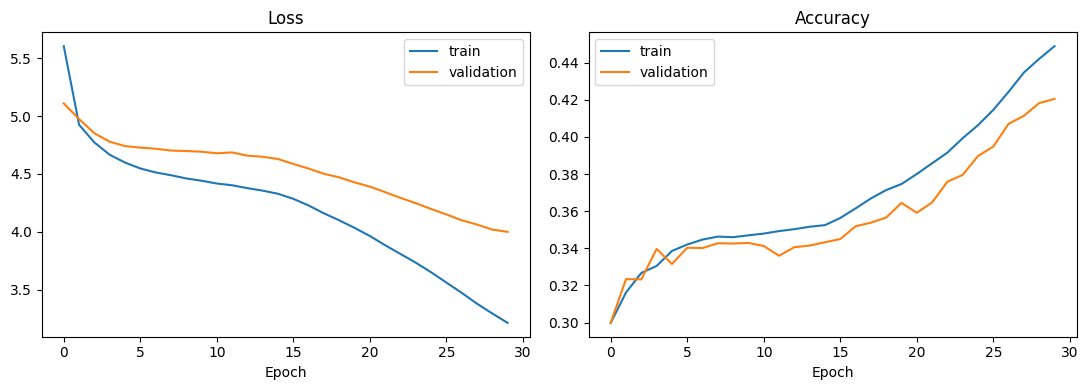

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.show()

**Evaluation on the test set.** Keras `accuracy` also counts the padding positions (which are easy to predict), so I also report accuracy on real words only and the percentage of sentences translated exactly like the reference.

In [15]:
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1), verbose=0)
print(f"Test loss: {loss:.4f} | Keras accuracy (includes padding): {accuracy:.4f}")

pred = np.argmax(model.predict(eng_test, verbose=0), axis=-1)
mask = frn_test != 0
word_acc = (pred[mask] == frn_test[mask]).mean()
exact = np.mean([(p[m] == t[m]).all() for p, t, m in zip(pred, frn_test, mask)])
print(f"Word accuracy (ignoring padding): {word_acc:.4f}")
print(f"Exact sentence match: {exact:.4f}")

Test loss: 3.9701 | Keras accuracy (includes padding): 0.4185
Word accuracy (ignoring padding): 0.1935
Exact sentence match: 0.0000


**Translating sentences.** First some sentences from the test set (with the reference translation), then new e-commerce style sentences.

In [16]:
def translate(sentence):
    seq = eng_tok.texts_to_sequences([clean(sentence)])
    seq = pad_sequences(seq, maxlen=MAX_LEN)
    ids = np.argmax(model.predict(seq, verbose=0), axis=-1)[0]
    return " ".join(frn_tok.index_word.get(i, "") for i in ids if i != 0)

# 1) sentences from the test set
print("--- Test set examples ---")
for i in range(8):
    eng = eng_tok.sequences_to_texts([eng_test[i]])[0]
    ref = frn_tok.sequences_to_texts([frn_test[i]])[0]
    print(f"EN : {eng}\nREF: {ref}\nMT : {translate(eng)}\n")

# 2) e-commerce style sentences
print("--- E-commerce examples ---")
samples = [
    "I love this product",
    "The shoes are too small",
    "Where is my order",
    "Free shipping on all orders",
    "Thank you very much",
    "This is very expensive",
]
for s in samples:
    print(f"EN: {s}\nFR: {translate(s)}\n")

--- Test set examples ---
EN : <unk> <unk> i promise you i'll come early
REF: je vous promets que je viendrai tôt <unk>
MT : je je je je je vous

EN : <unk> <unk> do what you want with it
REF: fais en ce que tu veux <unk> <unk>
MT : pourquoi tu tu tu faire

EN : <unk> <unk> i thought tom was a doctor
REF: je pensais que tom était médecin <unk> <unk>
MT : je sais que tom de un un

EN : <unk> <unk> <unk> <unk> they fought for freedom
REF: ils se sont battus pour la liberté <unk>
MT : le le est de de <unk>

EN : <unk> i'll show you how to do it
REF: je vous montrerai comment le faire <unk> <unk>
MT : je veux que tu tu vous faire

EN : <unk> <unk> <unk> <unk> i actually don't know
REF: en réalité je ne sais pas <unk> <unk>
MT : pourquoi ce je je ne pas

EN : <unk> where would you like to go first
REF: où aimerais tu aller en premier <unk> <unk>
MT : comment tu tu tu de

EN : <unk> <unk> <unk> <unk> <unk> i woke up
REF: je me suis réveillé <unk> <unk> <unk> <unk>
MT : le le de que tu

--- E

**Notes and limitations**
- This is a word-level encoder-decoder without attention, trained on a small sample of short sentences, so it works best on short, common sentences and will make mistakes on long or rare ones (rare words become `<unk>`).
- For a real e-commerce system the model could be improved with more data and training, an attention mechanism, or a pre-trained Transformer translation model, and evaluated with a metric such as BLEU.